# Customer Churn Analytics Platform
## 07 — Revenue Impact Analysis

**Objective:**  
Analyze customer revenue, monthly charges, historical revenue from churned customers, and revenue potentially at risk to understand the financial impact of customer churn.

### Analysis Goals
- Calculate core revenue KPIs
- Compare revenue between active and churned customers
- Analyze revenue across contract types
- Analyze revenue across tenure groups
- Investigate monthly charge behavior
- Quantify historical revenue associated with churned customers
- Estimate monthly revenue potentially at risk
- Identify high-value churned customers
- Analyze revenue exposure across risk categories
- Identify financially important customer segments
- Translate revenue findings into retention recommendations

In [1]:
# ============================================================
# CELL 01 — IMPORT LIBRARIES
# ============================================================

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [ ]:
# ============================================================
# VISUALIZATION THEME
# ============================================================

plt.style.use("dark_background")

sns.set_theme(
    style="darkgrid",
    context="notebook"
)

DARK_BG = "#0F172A"
CARD_BG = "#1E293B"
TEXT_COLOR = "#F8FAFC"
GRID_COLOR = "#334155"

ACTIVE_COLOR = "#216F3F"
CHURN_COLOR = "#A1343C"
DARK_BLUE = "#1F4E78"

plt.rcParams.update({
    "figure.facecolor": DARK_BG,
    "axes.facecolor": CARD_BG,
    "axes.edgecolor": GRID_COLOR,
    "axes.labelcolor": TEXT_COLOR,
    "axes.titlecolor": TEXT_COLOR,
    "xtick.color": TEXT_COLOR,
    "ytick.color": TEXT_COLOR,
    "grid.color": GRID_COLOR,
    "text.color": TEXT_COLOR,
    "figure.titlesize": 16,
    "axes.titlesize": 14,
    "axes.labelsize": 11
})

print("Visualization theme configured.")

Visualization theme configured.


In [3]:
# ============================================================
# LOAD FEATURE DATASET
# ============================================================

DATA_PATH = Path(
    "../data/processed/customer_churn_features.csv"
)

df = pd.read_csv(DATA_PATH)

print("Feature-engineered dataset loaded successfully.")
print(f"Rows    : {df.shape[0]:,}")
print(f"Columns : {df.shape[1]:,}")

Feature-engineered dataset loaded successfully.
Rows    : 7,043
Columns : 37


In [ ]:
# ============================================================
# INITIAL VALIDATION
# ============================================================

print("Missing values  :", df.isna().sum().sum())
print("Duplicate rows  :", df.duplicated().sum())
print("Unique customers:", df["customerid"].nunique())

Missing values  : 0
Duplicate rows  : 0
Unique customers: 7043


## REVENUE KPIs
### Business Question

What is the overall revenue scale of the customer base?

In [5]:
# ============================================================
# REVENUE KPIs
# ============================================================

total_revenue = df["totalcharges"].sum()

monthly_revenue = df["monthlycharges"].sum()

average_total_revenue = df["totalcharges"].mean()

average_monthly_charges = df["monthlycharges"].mean()

print("REVENUE OVERVIEW")
print("-" * 50)

print(f"Total Historical Revenue : €{total_revenue:,.2f}")
print(f"Total Monthly Revenue    : €{monthly_revenue:,.2f}")
print(f"Average Customer Revenue : €{average_total_revenue:,.2f}")
print(f"Average Monthly Charges  : €{average_monthly_charges:,.2f}")

REVENUE OVERVIEW
--------------------------------------------------
Total Historical Revenue : €16,056,168.70
Total Monthly Revenue    : €456,116.60
Average Customer Revenue : €2,279.73
Average Monthly Charges  : €64.76


## REVENUE BY CUSTOMER STATUS
### Business Question

How much historical revenue is associated with active versus churned customers?

In [ ]:
# ============================================================
# REVENUE BY CUSTOMER STATUS
# ============================================================

revenue_by_status = (
    df.groupby("churn")
    .agg(
        Customers=("customerid", "count"),
        Total_Revenue=("totalcharges", "sum"),
        Average_Revenue=("totalcharges", "mean"),
        Monthly_Revenue=("monthlycharges", "sum")
    )
)

revenue_by_status

,Customers,Total_Revenue,Average_Revenue,Monthly_Revenue
churn,,,,
no,5174,13193241.8,2549.911442,316985.75
yes,1869,2862926.9,1531.796094,139130.85


C:\Users\Kunde\AppData\Local\Temp\ipykernel_19296\510317882.py:50: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(


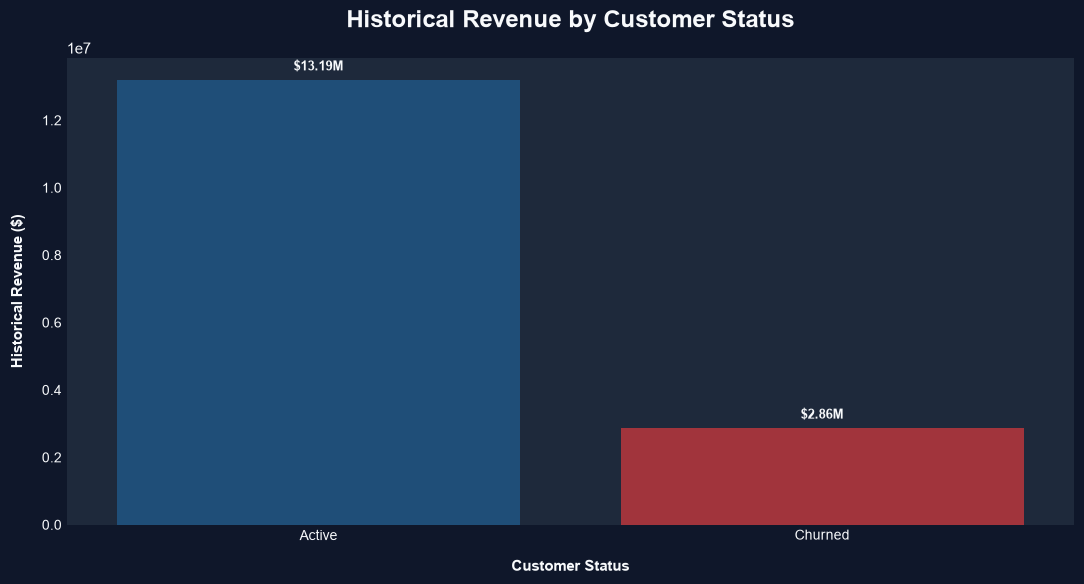

In [9]:
# ============================================================
# HISTORICAL REVENUE BY CUSTOMER STATUS
# Professional Portfolio Visualization
# ============================================================

revenue_plot = (
    revenue_by_status
    .reset_index()
)

plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=revenue_plot,
    x="churn",
    y="Total_Revenue",
    order=["no", "yes"],
    color=DARK_BLUE,
    edgecolor="none"
)

# Highlight churned revenue
for i, bar in enumerate(ax.patches):
    if revenue_plot.iloc[i]["churn"] == "yes":
        bar.set_facecolor(CHURN_COLOR)
    else:
        bar.set_facecolor(DARK_BLUE)

ax.set_title(
    "Historical Revenue by Customer Status",
    fontsize=17,
    fontweight="bold",
    pad=22
)

ax.set_xlabel(
    "Customer Status",
    fontsize=11,
    fontweight="bold",
    labelpad=12
)

ax.set_ylabel(
    "Historical Revenue ($)",
    fontsize=11,
    fontweight="bold",
    labelpad=12
)

ax.set_xticklabels(
    ["Active", "Churned"]
)

ax.grid(False)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.tick_params(
    axis="both",
    length=0,
    labelsize=10
)

# Currency labels
for bar in ax.containers[0]:
    height = bar.get_height()
    ax.annotate(
        f"${height / 1_000_000:.2f}M",
        (
            bar.get_x() + bar.get_width() / 2,
            height
        ),
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold",
        xytext=(0, 5),
        textcoords="offset points"
    )

plt.tight_layout()
plt.show()

## MONTHLY REVENUE BY CUSTOMER STATUS
### Business Question

How much current monthly revenue comes from active and churned customer groups?

In [11]:
# ============================================================
# MONTHLY REVENUE BY CUSTOMER STATUS
# ============================================================

monthly_revenue_status = (
    df.groupby("churn")
    .agg(
        Customers=("customerid", "count"),
        Monthly_Revenue=("monthlycharges", "sum"),
        Average_Monthly_Charges=("monthlycharges", "mean")
    )
)

monthly_revenue_status

,Customers,Monthly_Revenue,Average_Monthly_Charges
churn,,,
no,5174,316985.75,61.265124
yes,1869,139130.85,74.441332


C:\Users\Kunde\AppData\Local\Temp\ipykernel_19296\4240848492.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(


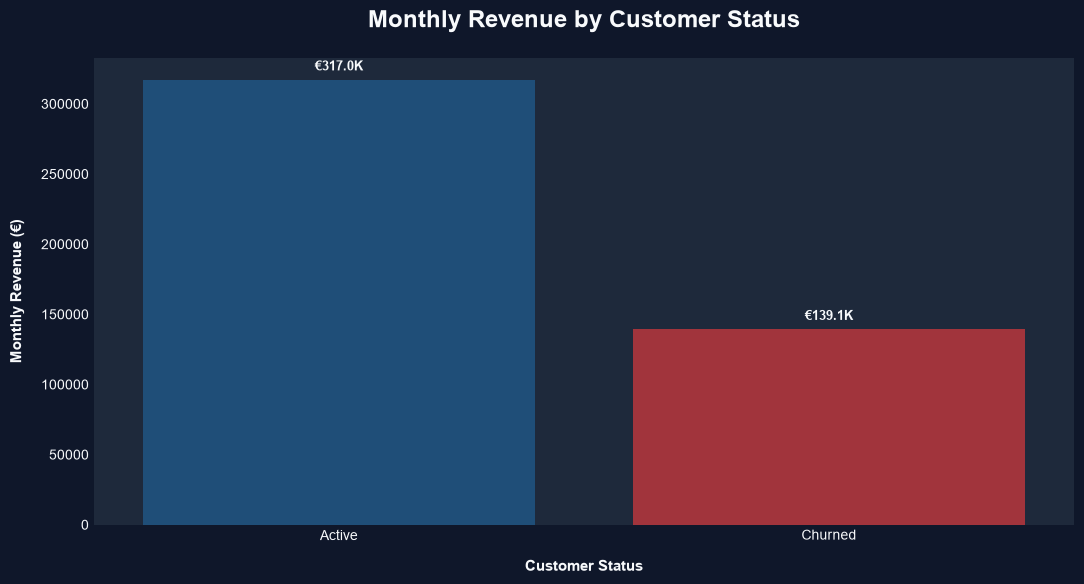

In [ ]:
# ============================================================
# MONTHLY REVENUE BY CUSTOMER STATUS
# Professional Portfolio Visualization
# ============================================================

monthly_plot = (
    monthly_revenue_status
    .reset_index()
)

plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=monthly_plot,
    x="churn",
    y="Monthly_Revenue",
    order=["no", "yes"],
    color=DARK_BLUE,
    edgecolor="none"
)

for i, bar in enumerate(ax.patches):
    if monthly_plot.iloc[i]["churn"] == "yes":
        bar.set_facecolor(CHURN_COLOR)
    else:
        bar.set_facecolor(DARK_BLUE)

ax.set_title(
    "Monthly Revenue by Customer Status",
    fontsize=17,
    fontweight="bold",
    pad=22
)

ax.set_xlabel(
    "Customer Status",
    fontsize=11,
    fontweight="bold",
    labelpad=12
)

ax.set_ylabel(
    "Monthly Revenue (€)",
    fontsize=11,
    fontweight="bold",
    labelpad=12
)

ax.set_xticklabels(
    ["Active", "Churned"]
)

ax.grid(False)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.tick_params(
    axis="both",
    length=0,
    labelsize=10
)

for bar in ax.containers[0]:
    height = bar.get_height()
    ax.annotate(
        f"€{height / 1000:.1f}K",
        (
            bar.get_x() + bar.get_width() / 2,
            height
        ),
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold",
        xytext=(0, 5),
        textcoords="offset points"
    )

plt.tight_layout()
plt.show()

## REVENUE BY CONTRACT
### Business Question

Which contract type generates the highest historical revenue?

In [ ]:
# ============================================================
# REVENUE BY CONTRACT
# ============================================================

contract_revenue = (
    df.groupby("contract")
    .agg(
        Customers=("customerid", "count"),
        Total_Revenue=("totalcharges", "sum"),
        Average_Revenue=("totalcharges", "mean"),
        Monthly_Revenue=("monthlycharges", "sum")
    )
    .sort_values(
        "Total_Revenue",
        ascending=False
    )
)

contract_revenue

,Customers,Total_Revenue,Average_Revenue,Monthly_Revenue
contract,,,,
Two year,1695,6283253.7,3706.934336,103005.85
Month-to-month,3875,5305861.5,1369.254581,257294.15
One year,1473,4467053.5,3032.622878,95816.60


In [ ]:
# ============================================================
# AVERAGE REVENUE BY CONTRACT
# ============================================================

contract_avg_revenue = (
    df.groupby("contract")["totalcharges"]
    .agg(
        Customers="count",
        Average_Revenue="mean"
    )
    .sort_values(
        "Average_Revenue",
        ascending=False
    )

)

contract_avg_revenue

,Customers,Average_Revenue
contract,,
Two year,1695,3706.934336
One year,1473,3032.622878
Month-to-month,3875,1369.254581


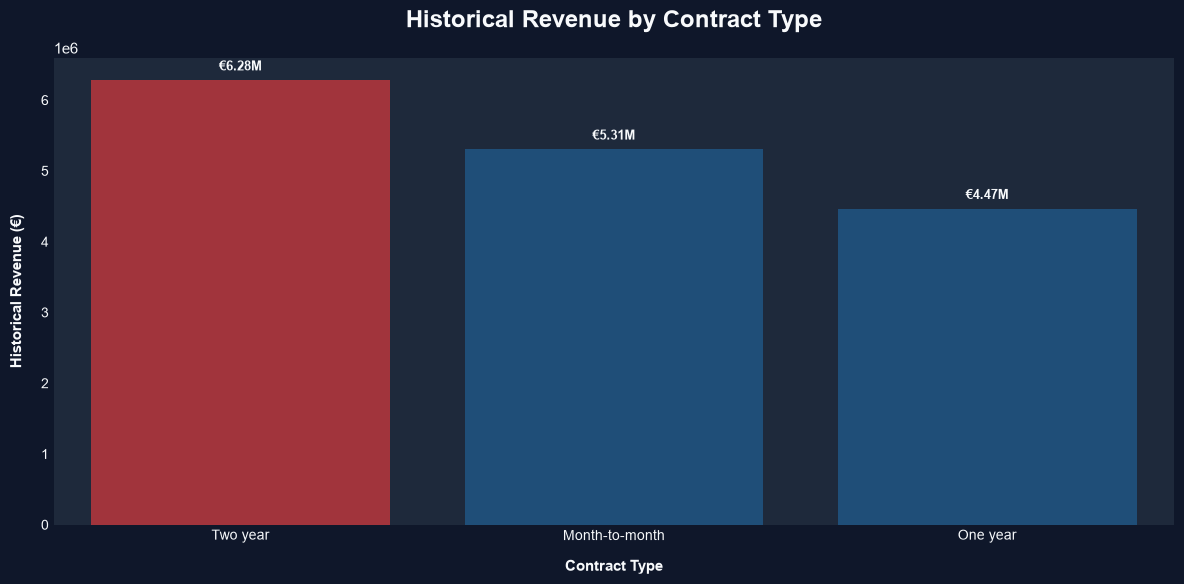

In [15]:
# ============================================================
# HISTORICAL REVENUE BY CONTRACT
# Professional Portfolio Visualization
# ============================================================

contract_plot = contract_revenue.reset_index()

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=contract_plot,
    x="contract",
    y="Total_Revenue",
    color=DARK_BLUE,
    edgecolor="none"
)

max_revenue = contract_plot["Total_Revenue"].max()

for i, (_, row) in enumerate(
    contract_plot.iterrows()
):
    if row["Total_Revenue"] == max_revenue:
        ax.patches[i].set_facecolor(CHURN_COLOR)
    else:
        ax.patches[i].set_facecolor(DARK_BLUE)

ax.set_title(
    "Historical Revenue by Contract Type",
    fontsize=17,
    fontweight="bold",
    pad=22
)

ax.set_xlabel(
    "Contract Type",
    fontsize=11,
    fontweight="bold",
    labelpad=12
)

ax.set_ylabel(
    "Historical Revenue (€)",
    fontsize=11,
    fontweight="bold",
    labelpad=12
)

ax.grid(False)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.tick_params(
    axis="both",
    length=0,
    labelsize=10
)

for bar in ax.containers[0]:
    height = bar.get_height()
    ax.annotate(
        f"€{height / 1_000_000:.2f}M",
        (
            bar.get_x() + bar.get_width() / 2,
            height
        ),
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold",
        xytext=(0, 5),
        textcoords="offset points"
    )

plt.tight_layout()
plt.show()

## REVENUE BY TENURE GROUP
### Business Question

Which tenure groups contribute the greatest historical revenue?

In [ ]:
# ============================================================
# REVENUE BY TENURE GROUP
# ============================================================

tenure_revenue = (
    df.groupby(
        "tenure_group",
        observed=False
    )
    .agg(
        Customers=("customerid", "count"),
        Total_Revenue=("totalcharges", "sum"),
        Average_Revenue=("totalcharges", "mean")
    )
)

tenure_revenue

,Customers,Total_Revenue,Average_Revenue
tenure_group,,,
0-12 Months,2186,601651.90,275.229597
13-24 Months,1024,1153287.70,1126.257520
25-48 Months,1594,3810380.35,2390.451913
49-72 Months,2239,10490848.75,4685.506364


In [17]:
# ============================================================
# CELL 14 — AVERAGE REVENUE BY TENURE
# ============================================================

tenure_avg_revenue = (
    df.groupby(
        "tenure_group",
        observed=False
    )["totalcharges"]
    .mean()
)

tenure_avg_revenue

tenure_group
0-12 Months      275.229597
13-24 Months    1126.257520
25-48 Months    2390.451913
49-72 Months    4685.506364
Name: totalcharges, dtype: float64

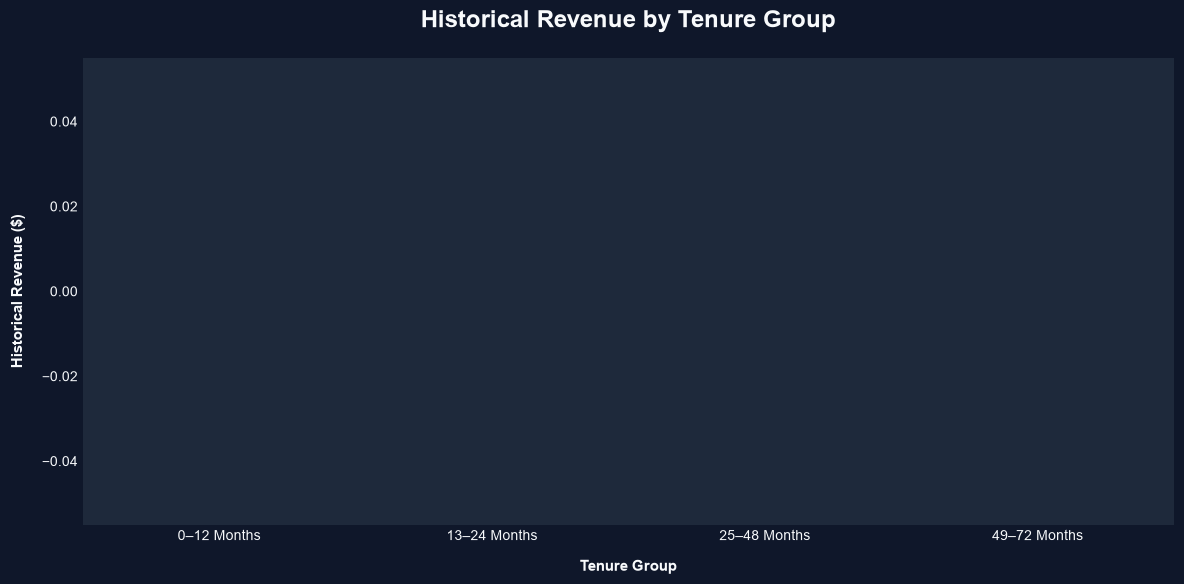

In [19]:
# ============================================================
# CELL 15 — HISTORICAL REVENUE BY TENURE GROUP
# Professional Portfolio Visualization
# ============================================================

tenure_revenue_plot = (
    tenure_revenue
    .reset_index()
)

tenure_order = [
    "0–12 Months",
    "13–24 Months",
    "25–48 Months",
    "49–72 Months"
]

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=tenure_revenue_plot,
    x="tenure_group",
    y="Total_Revenue",
    order=tenure_order,
    color=DARK_BLUE,
    edgecolor="none"
)

max_revenue = tenure_revenue_plot["Total_Revenue"].max()

for i, bar in enumerate(ax.patches):
    value = bar.get_height()

    if value == max_revenue:
        bar.set_facecolor(CHURN_COLOR)
    else:
        bar.set_facecolor(DARK_BLUE)

    ax.annotate(
        f"${value / 1_000_000:.2f}M",
        (
            bar.get_x() + bar.get_width() / 2,
            value
        ),
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold",
        xytext=(0, 5),
        textcoords="offset points"
    )

ax.set_title(
    "Historical Revenue by Tenure Group",
    fontsize=17,
    fontweight="bold",
    pad=22
)

ax.set_xlabel(
    "Tenure Group",
    fontsize=11,
    fontweight="bold",
    labelpad=12
)

ax.set_ylabel(
    "Historical Revenue ($)",
    fontsize=11,
    fontweight="bold",
    labelpad=12
)

ax.grid(False)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.tick_params(
    axis="both",
    length=0,
    labelsize=10
)

plt.tight_layout()
plt.show()